# Clase 44 · Reglas de asociación · sobre CAMMESA
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026 · Grupo 6**

Pregunta: ¿qué características de un agente del mercado eléctrico van **juntas** con qué comportamiento? Otro tipo de dato: una **canasta** es un conjunto de ítems, sin cantidades ni orden. No hay columna a predecir ni grupos: se buscan conjuntos que aparecen juntos más de lo que el azar explica, y en qué dirección (si esto, entonces aquello).

Tres partes: **1 · los datos** (una canasta por agente, con sus atributos y su comportamiento como ítems), **2 · el modelo** (soporte y confianza, Apriori, las reglas y las medidas que dicen si valen), **3 · usarlo** (qué esperar de un agente según dónde está y qué tarifa tiene, y la app Streamlit).

La biblioteca es **mlxtend** (`pip install mlxtend` si falta): scikit-learn no trae reglas de asociación.

## 1 · Los datos

### De agentes a canastas

CAMMESA no tiene tickets: no hay compras. Pero cada agente tiene **atributos** (región, si es distribuidor o gran usuario, tarifa, tamaño) y un **comportamiento** (los números de la clase 41). Se arma una canasta por agente con los dos como ítems. Los números se pasan a ítems con umbrales, y se dicen:

- **pico de verano** / **pico de invierno**: 20 % más en verano que en invierno, o al revés.
- **creciente** / **decreciente**: crece o cae más de 5 % por año.
- **volátil** / **estable**: el cuarto con más (o menos) variación mensual.
- **caídas frecuentes**: cayó más de 15 % en uno de cada cinco meses o más.
- **grande** / **chico**: el cuarto con más (o menos) demanda media.

Son las 868 series con al menos 24 meses de la clase 41.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
warnings.filterwarnings("ignore")

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
demanda = demanda.sort_values(["serie", "periodo"])
def perfil(g):
    """Los seis números de la clase 41."""
    s = g.set_index("periodo")["demanda_MWh"]
    if len(s) < 24 or (s <= 0).mean() > 0.1:
        return None
    pos = s[s > 0]
    cambio = (s / s.shift(1) - 1)[s.shift(1) > 0].clip(-1, 3)
    mes = pos.index.month
    verano, invierno = pos[np.isin(mes, [12, 1, 2])].mean(), pos[np.isin(mes, [6, 7, 8])].mean()
    anios = np.array([(p - pos.index[0]).n for p in pos.index]) / 12
    return pd.Series({"log_tamano": np.log10(pos.mean()), "estacionalidad": np.log2(verano / invierno),
                      "volatilidad": cambio.abs().median(), "tendencia_anual": np.polyfit(anios, np.log10(pos.to_numpy()), 1)[0],
                      "frac_caidas": (cambio < -0.15).mean(), "cv": pos.std() / pos.mean()})
perfiles = demanda.groupby("serie").apply(perfil).dropna()
atributos = demanda.groupby("serie")[["region", "categoria_demanda", "categoria_tarifa"]].first().loc[perfiles.index]
VOL_ALTA, VOL_BAJA = perfiles["volatilidad"].quantile([0.75, 0.25])
TAM_ALTO, TAM_BAJO = perfiles["log_tamano"].quantile([0.75, 0.25])
def a_items(serie):
    p, a = perfiles.loc[serie], atributos.loc[serie]
    items = {f"región {a['region'].title()}", "gran usuario" if a["categoria_demanda"] == "Gran Usuario" else "distribuidor", f"tarifa {a['categoria_tarifa'].split('/')[0].lower()}"}
    if p["log_tamano"] > TAM_ALTO: items.add("grande")
    elif p["log_tamano"] < TAM_BAJO: items.add("chico")
    if p["estacionalidad"] > np.log2(1.2): items.add("pico de verano")
    elif p["estacionalidad"] < -np.log2(1.2): items.add("pico de invierno")
    if p["tendencia_anual"] > np.log10(1.05): items.add("creciente")
    elif p["tendencia_anual"] < np.log10(0.95): items.add("decreciente")
    if p["volatilidad"] > VOL_ALTA: items.add("volátil")
    elif p["volatilidad"] < VOL_BAJA: items.add("estable")
    if p["frac_caidas"] >= 0.2: items.add("caídas frecuentes")
    return sorted(items)
canastas = [a_items(s) for s in perfiles.index]
codificador = TransactionEncoder()
M = pd.DataFrame(codificador.fit(canastas).transform(canastas), columns=codificador.columns_)   # la matriz binaria: una fila por agente, una columna por ítem
COMPORTAMIENTO = ["pico de verano", "pico de invierno", "creciente", "decreciente", "volátil", "estable", "caídas frecuentes"]
ATRIBUTOS = [c for c in M.columns if c not in COMPORTAMIENTO]
print("Tres canastas:"); [print(f"   {s}: {c}") for s, c in list(zip(perfiles.index, canastas))[:3]]
print(f"La matriz: {M.shape[0]} canastas × {M.shape[1]} ítems ({len(ATRIBUTOS)} de atributos, {len(COMPORTAMIENTO)} de comportamiento)")
M.head().astype(int)

Tres canastas:
   AARGTAOY | GUMAS/AUTOGENERADORES: ['gran usuario', 'pico de verano', 'región Gran Bs.As.', 'tarifa industrial']
   ABRILHCY | GUMAS/AUTOGENERADORES: ['gran usuario', 'región Gran Bs.As.', 'tarifa industrial']
   ACARQQ3Y | GUMAS/AUTOGENERADORES: ['caídas frecuentes', 'chico', 'creciente', 'gran usuario', 'región Buenos Aires', 'tarifa industrial', 'volátil']
La matriz: 868 canastas × 23 ítems (16 de atributos, 7 de comportamiento)


,caídas frecuentes,chico,creciente,decreciente,distribuidor,estable,gran usuario,grande,pico de invierno,pico de verano,...,región Cuyo,región Gran Bs.As.,región Litoral,región Noreste,región Noroeste,región Patagonica,tarifa comercial,tarifa industrial,tarifa residencial,volátil
0,0,0,0,0,0,0,1,0,0,1,...,0,1,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,1,0,0
2,1,1,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,1
3,1,1,0,0,0,0,1,0,0,0,...,0,0,1,0,0,0,0,1,0,1
4,0,0,0,0,0,0,1,1,1,0,...,0,0,0,0,0,0,0,1,0,0


### Cuánto aparece cada ítem, y cuántos ítems tiene una canasta

El **soporte** de un ítem es en qué fracción de las canastas está. «Tarifa industrial» está en el 61 %: es el ítem popular, como las Medias del ejemplo de la cátedra. Cada canasta tiene exactamente una región, un tipo de agente y una tarifa; los ítems de comportamiento pueden estar o no.

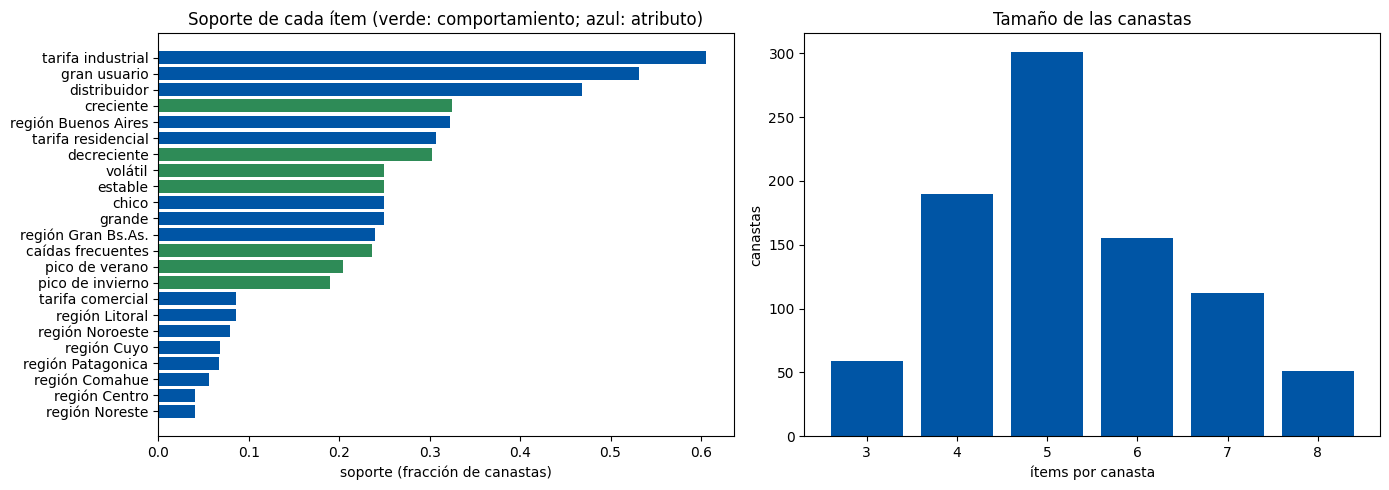

Soportes: {'tarifa industrial': 0.61, 'gran usuario': 0.53, 'distribuidor': 0.47, 'creciente': 0.32, 'región Buenos Aires': 0.32, 'tarifa residencial': 0.31, 'decreciente': 0.3, 'volátil': 0.25, 'estable': 0.25, 'chico': 0.25, 'grande': 0.25, 'región Gran Bs.As.': 0.24, 'caídas frecuentes': 0.24, 'pico de verano': 0.2, 'pico de invierno': 0.19, 'tarifa comercial': 0.09, 'región Litoral': 0.09, 'región Noroeste': 0.08, 'región Cuyo': 0.07, 'región Patagonica': 0.07, 'región Comahue': 0.06, 'región Centro': 0.04, 'región Noreste': 0.04}


In [2]:
soportes = M.mean().sort_values(ascending=False)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
a.barh(soportes.index, soportes.values, color=["#2e8b57" if i in COMPORTAMIENTO else "#0055a5" for i in soportes.index]); a.invert_yaxis()
a.set_xlabel("soporte (fracción de canastas)"); a.set_title("Soporte de cada ítem (verde: comportamiento; azul: atributo)")
tam = M.sum(axis=1).value_counts().sort_index(); b.bar(tam.index, tam.values, color="#0055a5"); b.set_xlabel("ítems por canasta"); b.set_ylabel("canastas"); b.set_title("Tamaño de las canastas")
plt.tight_layout(); plt.show()
print("Soportes:", soportes.round(2).to_dict())

## 2 · El modelo

### Soporte y confianza: dos conteos

Para un par de ítems: el **soporte** es en cuántas canastas están los dos; la **confianza** de A ⇒ B es, de las canastas que tienen A, qué fracción tiene B. Se calculan a mano para «región Noreste» y «pico de verano».

In [3]:
def cuenta(items): return int(M[list(items)].all(axis=1).sum())                  # canastas que tienen todos esos ítems
n = len(M)
A, B = "región Noreste", "pico de verano"
print(f"{A}: {cuenta([A])} canastas · {B}: {cuenta([B])} · los dos juntos: {cuenta([A, B])} → soporte {cuenta([A, B]) / n:.3f}")
print(f"Confianza({A} ⇒ {B}) = {cuenta([A, B])} / {cuenta([A])} = {cuenta([A, B]) / cuenta([A]):.2f}: de los agentes del Noreste, el {100 * cuenta([A, B]) / cuenta([A]):.0f} % tiene pico de verano")
print(f"Confianza({B} ⇒ {A}) = {cuenta([A, B])} / {cuenta([B])} = {cuenta([A, B]) / cuenta([B]):.2f}: la misma pareja, otra dirección, otra confianza")
print(f"Pero el pico de verano está en el {100 * cuenta([B]) / n:.0f} % de todos los agentes; en el Noreste, en el {100 * cuenta([A, B]) / cuenta([A]):.0f} %. Estar en el Noreste SUBE la chance de pico de verano. Eso es lo que mide la elevación.")

región Noreste: 35 canastas · pico de verano: 177 · los dos juntos: 18 → soporte 0.021
Confianza(región Noreste ⇒ pico de verano) = 18 / 35 = 0.51: de los agentes del Noreste, el 51 % tiene pico de verano
Confianza(pico de verano ⇒ región Noreste) = 18 / 177 = 0.10: la misma pareja, otra dirección, otra confianza
Pero el pico de verano está en el 20 % de todos los agentes; en el Noreste, en el 51 %. Estar en el Noreste SUBE la chance de pico de verano. Eso es lo que mide la elevación.


### Apriori: los conjuntos frecuentes

Con 23 ítems hay más de ocho millones de conjuntos posibles; con 100, más de 10³⁰. No se pueden contar todos. **Apriori** cuenta por niveles (de a 1, de a 2, de a 3…) y usa una regla para descartar sin contar: si un conjunto no es frecuente, ningún conjunto que lo contenga lo es. `apriori` recibe la matriz y el soporte mínimo, y devuelve los conjuntos frecuentes con su soporte.

1144 conjuntos frecuentes de 8,388,607 posibles · por tamaño: {1: 23, 2: 181, 3: 405, 4: 339, 5: 154, 6: 39, 7: 3}


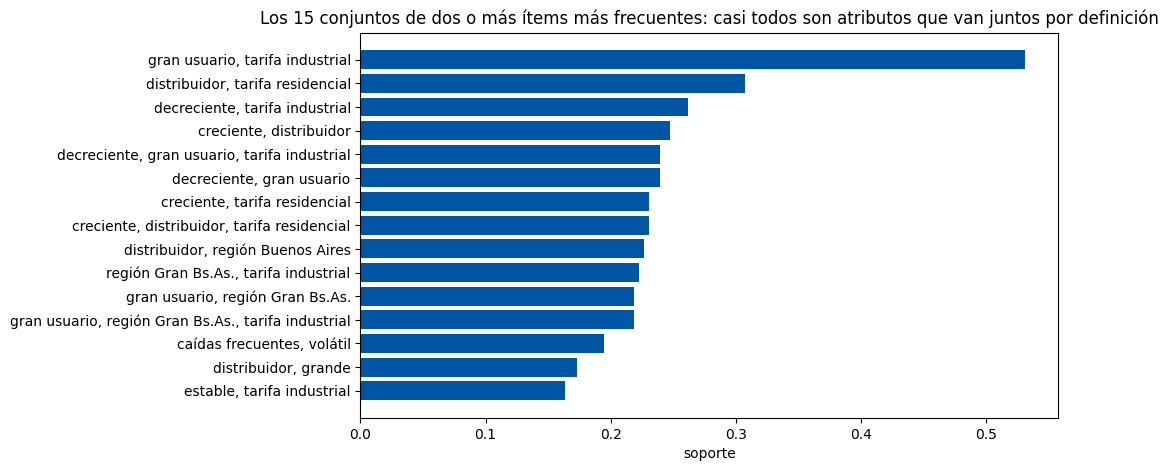

Frecuentes según el soporte mínimo: {0.2: 26, 0.1: 80, 0.05: 208, 0.02: 585, 0.01: 1144} · cuanto más bajo el mínimo, más frecuentes


In [4]:
frecuentes = apriori(M, min_support=0.01, use_colnames=True)                    # soporte mínimo: 1 % de las canastas (9 agentes)
frecuentes["tamaño"] = frecuentes["itemsets"].apply(len)
frecuentes["conjunto"] = frecuentes["itemsets"].apply(lambda s: ", ".join(sorted(s)))
print(f"{len(frecuentes)} conjuntos frecuentes de {2 ** M.shape[1] - 1:,} posibles · por tamaño: {frecuentes['tamaño'].value_counts().sort_index().to_dict()}")
fig, ax = plt.subplots(figsize=(9, 5))
top = frecuentes[frecuentes["tamaño"] >= 2].sort_values("support", ascending=False).head(15)
ax.barh(top["conjunto"], top["support"], color="#0055a5"); ax.invert_yaxis(); ax.set_xlabel("soporte")
ax.set_title("Los 15 conjuntos de dos o más ítems más frecuentes: casi todos son atributos que van juntos por definición")
plt.show()
cuantos = [len(apriori(M, min_support=ms, use_colnames=True)) for ms in [0.2, 0.1, 0.05, 0.02, 0.01]]
print("Frecuentes según el soporte mínimo:", dict(zip([0.2, 0.1, 0.05, 0.02, 0.01], cuantos)), "· cuanto más bajo el mínimo, más frecuentes")

### De frecuentes a reglas, y las medidas que dicen si valen

`association_rules` parte cada frecuente en antecedente ⇒ consecuente y calcula todas las medidas. **Confianza** sola engaña: «tarifa residencial ⇒ distribuidor» tiene confianza 1 y es una definición (toda tarifa residencial es de una distribuidora). La **elevación** compara contra el azar: confianza dividida por el soporte del consecuente; 1 es independencia, más de 1 es «juntos más que por azar». La **convicción** mide cuánto menos falla la regla que por azar, y tiene dirección.

Y una trampa propia de estos datos: «volátil» y «caídas frecuentes» salen de los mismos cambios mensuales, así que van juntas con elevación alta y no enseñan nada. Lo que sirve son las reglas que cruzan **un atributo ⇒ un comportamiento**.

In [5]:
reglas = association_rules(frecuentes, metric="confidence", min_threshold=0.0)    # todas las reglas, sin filtro
reglas["regla"] = [f"{{{', '.join(sorted(a))}}} ⇒ {{{', '.join(sorted(b))}}}" for a, b in zip(reglas["antecedents"], reglas["consequents"])]
columnas = ["regla", "support", "confidence", "lift", "conviction"]
simples = reglas[(reglas["antecedents"].apply(len) == 1) & (reglas["consequents"].apply(len) == 1)]
print("Las cinco reglas de mayor CONFIANZA (un ítem de cada lado): definiciones del tipo de agente y la tarifa")
display(simples.sort_values("confidence", ascending=False)[columnas].head(5).round(3).reset_index(drop=True))
print("Las seis de mayor ELEVACIÓN (un ítem de cada lado): arriba, la pareja obvia volátil ⇔ caídas frecuentes")
display(simples.sort_values("lift", ascending=False)[columnas].head(6).round(3).reset_index(drop=True))

es_atributo = lambda s: all(i in ATRIBUTOS for i in s)
es_comportamiento = lambda s: len(s) == 1 and all(i in COMPORTAMIENTO for i in s)
cruzadas = reglas[reglas["antecedents"].apply(es_atributo) & reglas["consequents"].apply(es_comportamiento)].copy()
cruzadas["largo"] = cruzadas["antecedents"].apply(len)
cruzadas = cruzadas.sort_values("largo").drop_duplicates(subset=["consequents", "support", "confidence"])   # sin repetir la misma regla con un atributo de más que no cambia nada
print(f"Las ocho mejores de las {len(cruzadas)} reglas ATRIBUTO ⇒ COMPORTAMIENTO, por elevación:")
display(cruzadas.sort_values("lift", ascending=False)[columnas].head(8).round(3).reset_index(drop=True))
print("Y las tres de menor elevación con antecedente común (en al menos 5 % de los agentes): lo que un atributo hace MENOS probable")
display(cruzadas[cruzadas["antecedent support"] >= 0.05].sort_values("lift")[columnas].head(3).round(3).reset_index(drop=True))

Las cinco reglas de mayor CONFIANZA (un ítem de cada lado): definiciones del tipo de agente y la tarifa


,regla,support,confidence,lift,conviction
0,{tarifa comercial} ⇒ {distribuidor},0.086,1.000,2.133,inf
1,{tarifa residencial} ⇒ {distribuidor},0.308,1.000,2.133,inf
2,{gran usuario} ⇒ {tarifa industrial},0.531,1.000,1.650,inf
3,{región Gran Bs.As.} ⇒ {tarifa industrial},0.222,0.928,1.531,5.464
4,{región Gran Bs.As.} ⇒ {gran usuario},0.219,0.913,1.720,5.418


Las seis de mayor ELEVACIÓN (un ítem de cada lado): arriba, la pareja obvia volátil ⇔ caídas frecuentes


,regla,support,confidence,lift,conviction
0,{volátil} ⇒ {caídas frecuentes},0.195,0.779,3.298,3.453
1,{caídas frecuentes} ⇒ {volátil},0.195,0.824,3.298,4.271
2,{región Noreste} ⇒ {pico de verano},0.021,0.514,2.522,1.639
3,{pico de verano} ⇒ {región Noreste},0.021,0.102,2.522,1.068
4,{grande} ⇒ {región Noreste},0.024,0.097,2.400,1.062
5,{región Noreste} ⇒ {grande},0.024,0.600,2.400,1.875


Las ocho mejores de las 317 reglas ATRIBUTO ⇒ COMPORTAMIENTO, por elevación:


,regla,support,confidence,lift,conviction
0,"{región Noreste, tarifa residencial} ⇒ {pico d...",0.013,0.733,3.596,2.985
1,"{distribuidor, región Noreste} ⇒ {pico de verano}",0.017,0.652,3.198,2.289
2,"{distribuidor, grande, tarifa industrial} ⇒ {e...",0.022,0.792,3.167,3.600
3,"{grande, región Gran Bs.As., tarifa industrial...",0.013,0.733,2.933,2.812
4,"{distribuidor, grande, región Noreste} ⇒ {pico...",0.013,0.579,2.839,1.891
5,"{región Gran Bs.As., tarifa residencial} ⇒ {cr...",0.013,0.917,2.822,8.101
6,"{región Litoral, tarifa residencial} ⇒ {volátil}",0.012,0.667,2.667,2.250
7,"{grande, región Noreste} ⇒ {pico de verano}",0.013,0.524,2.569,1.672


Y las tres de menor elevación con antecedente común (en al menos 5 % de los agentes): lo que un atributo hace MENOS probable


,regla,support,confidence,lift,conviction
0,"{distribuidor, grande} ⇒ {decreciente}",0.014,0.080,0.264,0.758
1,"{región Gran Bs.As., tarifa industrial} ⇒ {vol...",0.016,0.073,0.290,0.809
2,"{gran usuario, región Gran Bs.As.} ⇒ {volátil}",0.016,0.074,0.295,0.810


### Confianza contra elevación, todas las reglas

Cada punto es una regla. En rojo, las obvias (volátil con caídas, o hacia un ítem que es casi definición); en verde, las de un atributo hacia un comportamiento. Las interesantes están arriba (elevación alta), no necesariamente a la derecha.

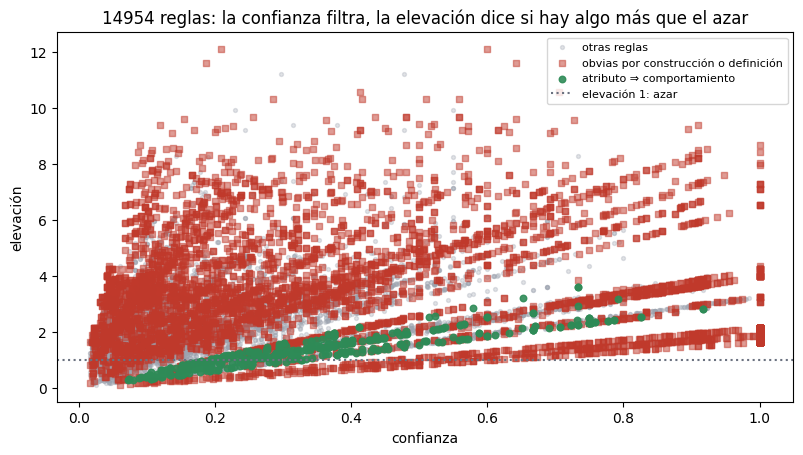

Reglas con elevación > 1: 13290 de 14954 · atributo ⇒ comportamiento con elevación > 1,5: 96


In [6]:
obvia = reglas.apply(lambda r: set(r["antecedents"] | r["consequents"]) >= {"volátil", "caídas frecuentes"} or r["consequents"] in (frozenset(["tarifa industrial"]), frozenset(["gran usuario"]), frozenset(["distribuidor"])), axis=1)
cruzada = reglas["antecedents"].apply(es_atributo) & reglas["consequents"].apply(es_comportamiento)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.scatter(reglas.loc[~obvia & ~cruzada, "confidence"], reglas.loc[~obvia & ~cruzada, "lift"], s=8, alpha=0.3, color="#9ca3af", label="otras reglas")
ax.scatter(reglas.loc[obvia, "confidence"], reglas.loc[obvia, "lift"], s=14, alpha=0.5, color="#c0392b", marker="s", label="obvias por construcción o definición")
ax.scatter(reglas.loc[cruzada, "confidence"], reglas.loc[cruzada, "lift"], s=22, alpha=0.9, color="#2e8b57", label="atributo ⇒ comportamiento")
ax.axhline(1, color="#6b7280", ls=":", label="elevación 1: azar"); ax.set_xlabel("confianza"); ax.set_ylabel("elevación"); ax.legend(fontsize=8)
ax.set_title(f"{len(reglas)} reglas: la confianza filtra, la elevación dice si hay algo más que el azar")
plt.show()
print(f"Reglas con elevación > 1: {(reglas['lift'] > 1).sum()} de {len(reglas)} · atributo ⇒ comportamiento con elevación > 1,5: {(cruzadas['lift'] > 1.5).sum()}")

Lo que dicen las verdes es del negocio eléctrico: las residenciales del **Noreste** tienen pico de verano (el aire acondicionado, en una región muy calurosa); las residenciales de varias regiones vienen **creciendo**; los grandes distribuidores industriales son **estables**; y los grandes usuarios industriales del Gran Buenos Aires casi nunca son volátiles ni crecientes. Que eso sirva lo dice quien conoce el mercado; el método lo saca de entre miles de reglas.

## 3 · Usarlo

### Qué esperar de un agente nuevo

Dado lo que se sabe de un agente que entra al mercado (región, tipo, tarifa, tamaño), las reglas atributo ⇒ comportamiento cuyo antecedente está contenido en eso, ordenadas por elevación, dicen qué comportamiento esperar. Se pide elevación mayor que 1,3.

In [7]:
utiles = cruzadas[cruzadas["lift"] > 1.3]
def esperar(agente, k=3):
    tiene = frozenset(agente)
    aplican = utiles[utiles["antecedents"].apply(lambda A: A <= tiene)]
    return aplican.sort_values("lift", ascending=False).drop_duplicates(subset="consequents").head(k)
for agente in [["región Noreste", "distribuidor", "tarifa residencial"], ["región Gran Bs.As.", "gran usuario", "tarifa industrial"], ["región Buenos Aires", "distribuidor", "tarifa residencial", "chico"], ["región Patagonica", "gran usuario", "tarifa industrial", "grande"]]:
    rec = esperar(agente)
    print(f"Agente {agente}: " + (" · ".join(f"esperar {', '.join(r.consequents)} (confianza {r.confidence:.0%}, elevación {r.lift:.2f})" for r in rec.itertuples()) if len(rec) else "nada que anticipar con elevación > 1,3"))

Agente ['región Noreste', 'distribuidor', 'tarifa residencial']: esperar pico de verano (confianza 73%, elevación 3.60) · esperar creciente (confianza 75%, elevación 2.31) · esperar volátil (confianza 45%, elevación 1.78)
Agente ['región Gran Bs.As.', 'gran usuario', 'tarifa industrial']: esperar decreciente (confianza 51%, elevación 1.68)
Agente ['región Buenos Aires', 'distribuidor', 'tarifa residencial', 'chico']: esperar creciente (confianza 76%, elevación 2.33) · esperar volátil (confianza 56%, elevación 2.24) · esperar caídas frecuentes (confianza 47%, elevación 1.98)
Agente ['región Patagonica', 'gran usuario', 'tarifa industrial', 'grande']: esperar estable (confianza 54%, elevación 2.15) · esperar caídas frecuentes (confianza 38%, elevación 1.59) · esperar decreciente (confianza 45%, elevación 1.49)


### Guardar

Las reglas atributo ⇒ comportamiento (con todas sus medidas), las listas de ítems y los soportes, en un archivo que la app carga.

In [8]:
import joblib
regiones = sorted(c for c in ATRIBUTOS if c.startswith("región"))
joblib.dump({"reglas": cruzadas, "regiones": regiones, "comportamiento": COMPORTAMIENTO, "soportes": soportes.to_dict()}, "reglas_cammesa_44.joblib")
print(f"Guardado: reglas_cammesa_44.joblib ({len(cruzadas)} reglas atributo ⇒ comportamiento)")

Guardado: reglas_cammesa_44.joblib (317 reglas atributo ⇒ comportamiento)


### La aplicación Streamlit, desde el cuaderno

La celda siguiente escribe `app_cammesa_44.py` (se eligen la región, el tipo de agente, la tarifa y el tamaño, y la app dice qué comportamiento esperar, con la regla que lo justifica). La de después la abre.

In [9]:
%%writefile app_cammesa_44.py
# Clase 44 sobre CAMMESA · Reglas de asociación · aplicación Streamlit
# Carga las reglas guardadas por el cuaderno y, con lo que se sabe de un agente, dice qué comportamiento esperar.
# Para abrirla:  streamlit run app_cammesa_44.py
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

st.set_page_config(page_title="¿Qué esperar de este agente?", layout="centered")
st.title("¿Qué comportamiento esperar de este agente?")
st.caption("Reglas de asociación (Apriori + association_rules) sobre 868 agentes de demanda-ltimos-aos.csv (CAMMESA, clase 44): atributo ⇒ comportamiento.")

g = joblib.load("reglas_cammesa_44.joblib")
reglas, regiones, soportes = g["reglas"], g["regiones"], g["soportes"]
nombre = lambda s: ", ".join(sorted(s))

st.subheader("Lo que se sabe del agente")
c1, c2 = st.columns(2)
region = c1.selectbox("Región", regiones, format_func=lambda r: r.replace("región ", ""))
tipo = c1.radio("Tipo de agente", ["distribuidor", "gran usuario"])
tarifa = c2.radio("Tarifa", ["tarifa residencial", "tarifa comercial", "tarifa industrial"])
tamano = c2.radio("Tamaño", ["no sé / mediano", "grande", "chico"])
minimo_elevacion = st.slider("Elevación mínima", 1.0, 3.0, 1.3, step=0.1)

tiene = frozenset([region, tipo, tarifa] + ([tamano] if tamano in ("grande", "chico") else []))
aplican = reglas[reglas["antecedents"].apply(lambda A: A <= tiene) & (reglas["lift"] >= minimo_elevacion)].sort_values("lift", ascending=False)
mejores = aplican.drop_duplicates(subset="consequents").head(5)                     # una fila por comportamiento: la regla de mayor elevación

st.subheader("Qué esperar")
if len(mejores) == 0:
    st.write("Ninguna regla con esa elevación aplica: con estos datos, nada en este agente hace un comportamiento más probable que el promedio.")
else:
    for r in mejores.itertuples():
        c = nombre(r.consequents)
        st.write(f"**{c}** · porque {{{nombre(r.antecedents)}}} ⇒ {{{c}}}: confianza {r.confidence:.0%} (contra {soportes[c]:.0%} en todos los agentes), elevación {r.lift:.2f}, soporte {r.support:.1%}")
    fig, ax = plt.subplots(figsize=(8, 3.2))
    etiquetas = [nombre(r.consequents) for r in mejores.itertuples()]
    ax.barh(etiquetas, mejores["lift"], color="#2e8b57"); ax.axvline(1, color="#c0392b", ls="--", label="elevación 1: azar")
    for y, (l, cf) in enumerate(zip(mejores["lift"], mejores["confidence"])): ax.text(l + 0.05, y, f"confianza {cf:.0%}", va="center", fontsize=9)
    ax.set_xlabel("elevación"); ax.invert_yaxis(); ax.legend(loc="lower right"); ax.set_title("Lo que este agente hace más probable que el promedio")
    st.pyplot(fig)

with st.expander("Ver todas las reglas que aplican"):
    muestra = aplican.copy(); muestra["regla"] = [f"{{{nombre(a)}}} ⇒ {{{nombre(b)}}}" for a, b in zip(muestra["antecedents"], muestra["consequents"])]
    st.dataframe(muestra[["regla", "support", "confidence", "lift", "conviction"]].round(3).reset_index(drop=True))

Writing app_cammesa_44.py


La celda que sigue abre la app. Mientras corre, la celda queda ocupada; para volver se interrumpe el kernel (■).

In [10]:
!streamlit run app_cammesa_44.py

^C


### Y lo que estas canastas no tienen

Las reglas de arriba describen agentes; no son compras, y dependen de los umbrales elegidos para pasar números a ítems (con otros, cambian algunos soportes y algunas reglas). Una pregunta de canasta de verdad en el mercado eléctrico sería «cuando cae fuerte un agente, ¿qué otros caen el mismo mes?»: una canasta por mes con los agentes que cayeron. Con 38 meses de datos son muy pocas canastas para reglas confiables; con datos diarios o por hora, sí. Es el equivalente del identificador de ticket que le faltaba al sistema de ventas en el ejemplo de la cátedra.

## Qué quedó

- Una canasta es un conjunto de ítems. **Soporte**: en cuántas canastas está el conjunto; **confianza** de A ⇒ B: de las canastas con A, cuántas tienen B. Dos conteos.
- **Apriori** encuentra los conjuntos frecuentes sin contar los más de ocho millones posibles: por niveles, descartando lo que contiene algo infrecuente. `apriori(M, min_support)` y `association_rules(frecuentes, metric)`.
- La confianza sola engaña (las definiciones tienen confianza 1), y la elevación también, cuando dos ítems salen del mismo dato (volátil y caídas frecuentes). Lo que sirve son las reglas **atributo ⇒ comportamiento**: residencial del Noreste ⇒ pico de verano; residencial ⇒ creciente; gran usuario industrial del Gran Buenos Aires ⇒ ni volátil ni creciente.
- Con lo que se sabe de un agente, las reglas que aplican dicen qué esperar. Las reglas de asociación funcionan sobre descripciones, no solo sobre compras, siempre que se digan los umbrales.